<a href="https://colab.research.google.com/github/mmcassel/sprint4-final-project/blob/main/sprint4_final_project_starter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Sprint 4 Project: E-Commerce Customer Behavior EDA

Welcome to your Sprint 4 final project. In this project, you will apply everything you've learned across Sprints 1–4 to perform a complete Exploratory Data Analysis on the **Olist Brazilian E-Commerce dataset** — real data from a real e-commerce platform.


## Dataset

You'll work with 7 CSV files from the Olist e-commerce dataset:

| File | Rows | Description |
|---|---|---|
| `olist_orders_dataset.csv` | 99,441 | Orders with timestamps and status |
| `olist_order_items_dataset.csv` | 112,650 | Items per order with price and freight |
| `olist_customers_dataset.csv` | 99,441 | Customer ID, city, state |
| `olist_products_dataset.csv` | 32,951 | Products with category and dimensions |
| `olist_order_reviews_dataset.csv` | 99,224 | Review scores (1–5 stars) |
| `olist_order_payments_dataset.csv` | 103,886 | Payment type and value |
| `product_category_name_translation.csv` | 71 | Portuguese → English category names |

Let's get started!

---

## Setup

Run the cells below to import the libraries you'll need and load the datasets. The data is hosted on GitHub, so you can load it with one line of code per file — no uploads required.

In [14]:
# Import libraries
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt

# Confirm versions
print(f"pandas version: {pd.__version__}")
print("Setup complete!")

pandas version: 2.2.3
Setup complete!


In [15]:
# Load the 7 datasets from the curriculum GitHub repo
BASE_URL = 'https://practicum-content.s3.us-west-1.amazonaws.com/data-analytics/eda-project/'

orders = pd.read_csv(BASE_URL + 'olist_orders_dataset.csv')
items = pd.read_csv(BASE_URL + 'olist_order_items_dataset.csv')
customers = pd.read_csv(BASE_URL + 'olist_customers_dataset.csv')
products = pd.read_csv(BASE_URL + 'olist_products_dataset.csv')
reviews = pd.read_csv(BASE_URL + 'olist_order_reviews_dataset.csv')
payments = pd.read_csv(BASE_URL + 'olist_order_payments_dataset.csv')
translation = pd.read_csv(BASE_URL + 'product_category_name_translation.csv')

print(f"orders:      {orders.shape}")
print(f"items:       {items.shape}")
print(f"customers:   {customers.shape}")
print(f"products:    {products.shape}")
print(f"reviews:     {reviews.shape}")
print(f"payments:    {payments.shape}")
print(f"translation: {translation.shape}")

orders:      (99441, 8)
items:       (112650, 7)
customers:   (99441, 5)
products:    (32951, 9)
reviews:     (99224, 7)
payments:    (103886, 5)
translation: (71, 2)


In [16]:
# Set up an in-memory SQLite database with all 7 tables
# This lets you run SQL queries directly against the DataFrames
conn = sqlite3.connect(':memory:')

orders.to_sql('orders', conn, index=False, if_exists='replace')
items.to_sql('items', conn, index=False, if_exists='replace')
customers.to_sql('customers', conn, index=False, if_exists='replace')
products.to_sql('products', conn, index=False, if_exists='replace')
reviews.to_sql('reviews', conn, index=False, if_exists='replace')
payments.to_sql('payments', conn, index=False, if_exists='replace')
translation.to_sql('translation', conn, index=False, if_exists='replace')

print("SQLite database ready. You can now run SQL queries with pd.read_sql().")

SQLite database ready. You can now run SQL queries with pd.read_sql().


---

## Question 1: Inspect the orders DataFrame

**Your task:** For the `orders` DataFrame:
1. Print its shape
2. Print the first 5 rows with `.head()`
3. Print column info with `.info()`

This is the very first thing every analyst does with a new dataset.

*Skills: Sprint 4 Ch 01 (Pandas inspection)*

In [17]:
print(orders.shape)
print()
print(orders.head())
print()
orders.info()


(99441, 8)

                           order_id                       customer_id  \
0  e481f51cbdc54678b7cc49136f2d6af7  9ef432eb6251297304e76186b10a928d   
1  53cdb2fc8bc7dce0b6741e2150273451  b0830fb4747a6c6d20dea0b8c802d7ef   
2  47770eb9100c2d0c44946d9cf07ec65d  41ce2a54c0b03bf3443c3d931a367089   
3  949d5b44dbf5de918fe9c16f97b45f8a  f88197465ea7920adcdbec7375364d82   
4  ad21c59c0840e6cb83a9ceb5573f8159  8ab97904e6daea8866dbdbc4fb7aad2c   

  order_status order_purchase_timestamp    order_approved_at  \
0    delivered      2017-10-02 10:56:33  2017-10-02 11:07:15   
1    delivered      2018-07-24 20:41:37  2018-07-26 03:24:27   
2    delivered      2018-08-08 08:38:49  2018-08-08 08:55:23   
3    delivered      2017-11-18 19:28:06  2017-11-18 19:45:59   
4    delivered      2018-02-13 21:18:39  2018-02-13 22:20:29   

  order_delivered_carrier_date order_delivered_customer_date  \
0          2017-10-04 19:55:00           2017-10-10 21:25:13   
1          2018-07-26 14:31:00      

**Observations**
- The orders table has 99,441 rows and 8 columns.
- The approval, carrier delivery and customer delivery timestamps contain null values (160, 1,783 and 2,965 missing, respectively), likely from orders that were canceled or never delivered.
- The timestamp columns are stored as text ('object') and may need to be converted with pd.to_datetime() for calculations.

---

## Question 2: Clean the orders data

The `orders` DataFrame has timestamp columns stored as strings, and a few have missing values.

**Your task:**
1. Use `.isnull().sum()` to count missing values in each column of `orders`
2. Convert `order_purchase_timestamp` and `order_delivered_customer_date` to datetime using `pd.to_datetime()`
3. Print the dtypes after conversion to verify

*Skills: Sprint 4 Ch 02 (Cleaning, dtype conversion)*

In [18]:
print(orders.isnull().sum())
print()
orders['order_purchase_timestamp'] = pd.to_datetime(orders['order_purchase_timestamp'])
orders['order_delivered_customer_date'] = pd.to_datetime(orders['order_delivered_customer_date'])
print(orders.dtypes)


order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

order_id                                 object
customer_id                              object
order_status                             object
order_purchase_timestamp         datetime64[ns]
order_approved_at                        object
order_delivered_carrier_date             object
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date            object
dtype: object


---

## Question 3: Order status breakdown (SQL)

**Your task:** Write a SQL query against the `orders` table that returns:
- `order_status`
- `num_orders` — count of orders with that status
- `pct` — percentage of total orders, rounded to 2 decimals

Sort by `num_orders` descending. Save the result to a DataFrame called `status_summary` and print it.

**Hint:** Use `pd.read_sql("...", conn)`. The percentage trick is `COUNT(*) * 100.0 / (SELECT COUNT(*) FROM orders)`.

*Skills: Sprint 2 (SQL aggregation), Sprint 4 Ch 03 (Descriptive stats)*

In [19]:
query = """
    SELECT order_status,
           COUNT(*) AS num_orders,
           ROUND(COUNT(*) * 100.0 / (SELECT COUNT(*) FROM orders), 2) AS pct
    FROM orders
    GROUP BY order_status
    ORDER BY num_orders DESC
"""
status_summary = pd.read_sql(query, conn)
print(status_summary)



  order_status  num_orders    pct
0    delivered       96478  97.02
1      shipped        1107   1.11
2     canceled         625   0.63
3  unavailable         609   0.61
4     invoiced         314   0.32
5   processing         301   0.30
6      created           5   0.01
7     approved           2   0.00


---

## Question 4: Top 10 highest-revenue orders (SQL JOIN)

Each order can have multiple items. Total order revenue = sum of `price + freight_value` across all its items.

**Your task:** Write a SQL query that JOINs `orders` and `items` to find the **10 highest-revenue orders**. Return:
- `order_id`
- `order_status`
- `total_revenue` — rounded to 2 decimals

Save the result to `top_orders` and print it.

*Skills: Sprint 2 (SQL JOIN, GROUP BY), Sprint 4 Ch 06 (combining tables)*

In [20]:
query = """
    SELECT o.order_id,
           o.order_status,
           ROUND(SUM(i.price + i.freight_value), 2) AS total_revenue
    FROM orders AS o
    JOIN items AS i
        ON o.order_id = i.order_id
    GROUP BY o.order_id, o.order_status
    ORDER BY total_revenue DESC
    LIMIT 10
"""
top_orders = pd.read_sql(query, conn)
print(top_orders)


                           order_id order_status  total_revenue
0  03caa2c082116e1d31e67e9ae3700499    delivered       13664.08
1  736e1922ae60d0d6a89247b851902527    delivered        7274.88
2  0812eb902a67711a1cb742b3cdaa65ae    delivered        6929.31
3  fefacc66af859508bf1a7934eab1e97f    delivered        6922.21
4  f5136e38d1a14a4dbd87dff67da82701    delivered        6726.66
5  2cc9089445046817a7539d90805e6e5a    delivered        6081.54
6  a96610ab360d42a2e5335a3998b4718a    delivered        4950.34
7  b4c4b76c642808cbe472a32b86cddc95     canceled        4809.44
8  199af31afc78c699f0dbf71fb178d4d4    delivered        4764.34
9  8dbc85d1447242f3b127dda390d56e19    delivered        4681.78


**Observations:**
- The highest revenue order (R\$13,664.08) is nearly double the amount of the next highest order (R\$7,274.88) making it a significant outlier.
-  9 of the top 10 orders were delivered; one canceled order (R\$4,809.44) appears in the top 10. Revenue analyses may need to filter to delivered orders to reflect actual sales.
- Order revenue is right-skewed: a small number of high-value orders sit far above typical order values.

---

## Question 5: English product categories (pandas merge)

The `products` table has a Portuguese category column called `product_category_name`. The `translation` table maps each Portuguese name to its English equivalent.

**Your task:**
1. Use `products.merge(translation, on='product_category_name', how='left')` to add the English column. Save it to `products_eng`.
2. Find the **top 10 categories by number of products** using `value_counts()` on the `product_category_name_english` column. Save to `top_categories` and print it.

*Skills: Sprint 4 Ch 06 (pandas merge), Ch 03 (value_counts)*

In [21]:

products_eng = products.merge(translation, on='product_category_name', how='left')
top_categories = products_eng['product_category_name_english'].value_counts().head(10)
print(top_categories)
print()
print("Products with no English category:", products_eng['product_category_name_english'].isnull().sum())


product_category_name_english
bed_bath_table           3029
sports_leisure           2867
furniture_decor          2657
health_beauty            2444
housewares               2335
auto                     1900
computers_accessories    1639
toys                     1411
watches_gifts            1329
telephony                1134
Name: count, dtype: int64

Products with no English category: 623


**Observations:**
-  623 products have no English category listing. These products are excluded from the category counts.

---

## Question 6: Revenue and average review score by category

Now you'll combine three tables and compute multiple metrics per category.

**Your task:**
1. Build a DataFrame that merges `items` with `products_eng` (to get categories), then merges with `reviews` (to get scores). The shared key chain is: `items.product_id → products_eng.product_id` and `items.order_id → reviews.order_id`.
2. Add a `revenue` column = `price + freight_value`
3. Group by `product_category_name_english` and aggregate:
   - `total_revenue` = sum of `revenue`
   - `avg_review` = mean of `review_score`
   - `n_items` = count of `order_id`
4. Sort by `total_revenue` descending and show the **top 10 categories**. Save to `category_summary`.

*Skills: Sprint 4 Ch 06 (multi-table merge, groupby with multiple aggregations)*

In [22]:
# Step 1: merge items with products_eng to get the categories
df = items.merge(products_eng, on='product_id')

# Step 2: merge with reviews to get the review scores
df = df.merge(reviews, on='order_id')

# Step 3: add the revenue column
df['revenue'] = df['price'] + df['freight_value']
category_summary = (df.groupby('product_category_name_english')
                      .agg(total_revenue=('revenue', 'sum'),
                           avg_review=('review_score', 'mean'),
                           n_items=('order_id', 'count'))
                      .sort_values('total_revenue', ascending=False)
                      .head(10))
print(category_summary)


                               total_revenue  avg_review  n_items
product_category_name_english                                    
health_beauty                     1434501.78    4.142768     9645
watches_gifts                     1297404.23    4.019160     5950
bed_bath_table                    1244950.00    3.895663    11137
sports_leisure                    1155295.28    4.107986     8640
computers_accessories             1062184.42    3.930819     7849
furniture_decor                    902472.18    3.903493     8331
housewares                         775827.36    4.055019     6943
cool_stuff                         712954.07    4.146341     3772
auto                               678859.45    4.065512     4213
garden_tools                       581483.25    4.042735     4329


**Observations:**
- Average review scores for the top 10 revenue categories are tightly grouped, ranging from 3.896 to 4.146. Category does not appear to strongly affect customer satisfaction among the highest-revenue categories.
- The bed_bath_table category has the lowest average score (3.896) among the top 10, which may be worth investigating since it is a high revenue category with the highest order count (11,137).

---

## Question 7: Top 10 customer states (SQL + bar chart)

**Your task:**
1. Write a SQL query that returns the **top 10 customer states** by number of customers. Columns: `customer_state`, `num_customers`. Save to `state_top10`.
2. Create a **bar chart** of `num_customers` by `customer_state`. Add a title and rotate the x-tick labels if they overlap.

*Skills: Sprint 2 (SQL GROUP BY), Sprint 4 Ch 04 (bar chart)*

  customer_state  num_customers
0             SP          41746
1             RJ          12852
2             MG          11635
3             RS           5466
4             PR           5045
5             SC           3637
6             BA           3380
7             DF           2140
8             ES           2033
9             GO           2020



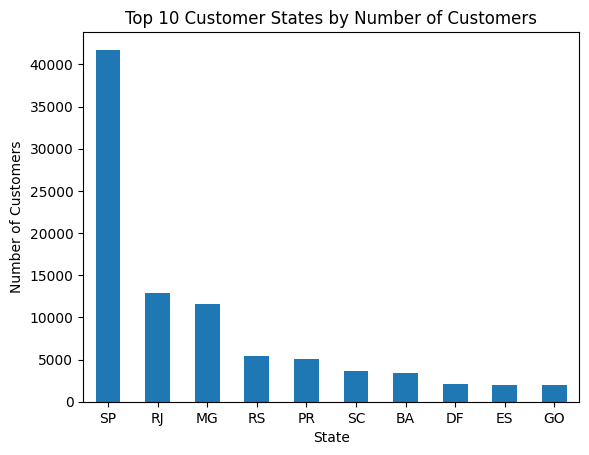

In [23]:
query = """
    SELECT customer_state,
           COUNT(*) AS num_customers
    FROM customers
    GROUP BY customer_state
    ORDER BY num_customers DESC
    LIMIT 10
"""
state_top10 = pd.read_sql(query, conn)
print(state_top10)
print()

state_top10.plot(kind='bar', x='customer_state', y='num_customers',
                 title='Top 10 Customer States by Number of Customers',
                xlabel = 'State' , ylabel = 'Number of Customers', legend = False, rot = 0)

plt.show()

**Observations:**
- São Paulo has the heaviest customer concentration, with about 1.4 times as many customers as the next 3 states combined. The customer base is heavily concentrated in SE Brazil.
- In the `customers` table, `customer_id` is created per order, so repeat customers get a new ID for each order. `COUNT(*) AS num_customers` is really counting orders. To count unique customers, use `COUNT(DISTINCT customer_unique_id)`.

---

## Question 8: Monthly order trend (line chart)

**Your task:**
1. From the cleaned `orders` DataFrame (with datetime columns from Q2), extract a `year_month` period from `order_purchase_timestamp` using `.dt.to_period('M')`
2. Count orders per month — save to a DataFrame called `monthly_orders` with columns `year_month` and `num_orders`
3. Plot a **line chart** of `num_orders` over time. Add a title.

**Hint:** `orders['order_purchase_timestamp'].dt.to_period('M').value_counts().sort_index()` is a fast way to get monthly counts. Convert the period index back to string for plotting.

*Skills: Sprint 4 Ch 02 (datetime), Ch 03 (groupby), Ch 04 (line chart)*

   year_month  num_orders
0     2016-09           4
1     2016-10         324
2     2016-12           1
3     2017-01         800
4     2017-02        1780
5     2017-03        2682
6     2017-04        2404
7     2017-05        3700
8     2017-06        3245
9     2017-07        4026
10    2017-08        4331
11    2017-09        4285
12    2017-10        4631
13    2017-11        7544
14    2017-12        5673
15    2018-01        7269
16    2018-02        6728
17    2018-03        7211
18    2018-04        6939
19    2018-05        6873
20    2018-06        6167
21    2018-07        6292
22    2018-08        6512
23    2018-09          16
24    2018-10           4


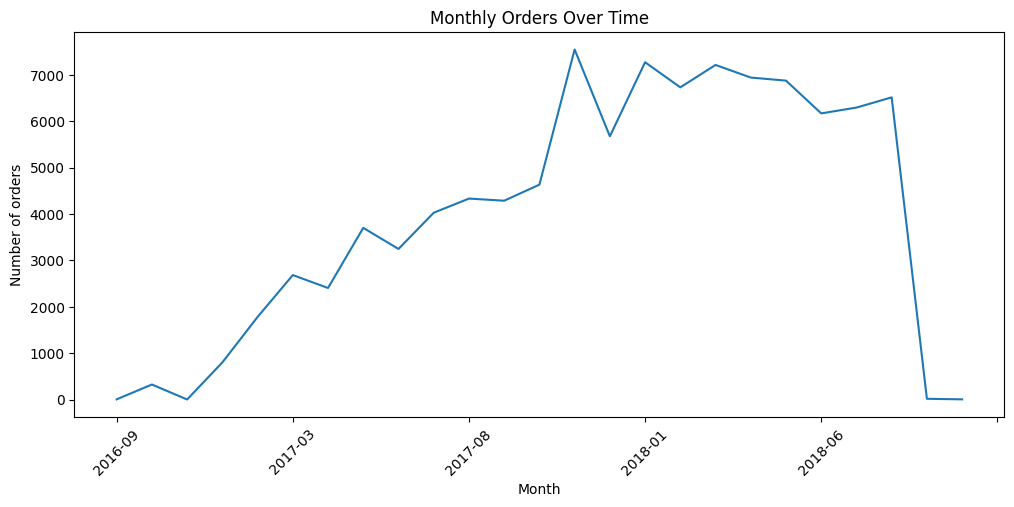


2018-10-17 17:30:18


In [24]:
# Extract year-month from the purchase timestamp
orders['year_month'] = orders['order_purchase_timestamp'].dt.to_period('M')

# Count orders per month
monthly_orders = orders['year_month'].value_counts().sort_index().reset_index()
monthly_orders.columns = ['year_month', 'num_orders']

# Convert the period to a string for plotting
monthly_orders['year_month'] = monthly_orders['year_month'].astype(str)

print(monthly_orders)

# Plot the trend
monthly_orders.plot(x='year_month', y='num_orders', kind='line',
                    title='Monthly Orders Over Time',
                    xlabel='Month', ylabel='Number of orders',
                    legend=False, rot=45, figsize=(12, 5))
plt.show()
print()
print(orders['order_purchase_timestamp'].max())


**Observations:**
- Monthly orders grew steadily through 2017, peaking in November 2017 (7,544 orders, likely due to Black Friday), then stayed high but relatively flat through most of 2018 (about 6,100–7,300 orders per month).
- The data is incomplete at both ends. In 2016, September has only 4 orders, October has 324, November has no orders at all, and December has 1. Consistent data begins in January 2017.
- The last order date in this data set is 10/17/2018. September 2018 has only 16 orders and October 2018 has 4, which causes the sharp drop at the end of the line chart. These months should not be considered accurate.
- Reliable trend analysis should focus on January 2017 through August 2018.

---

## Question 9: Does delivery speed affect review scores?

This is a real business question: do customers who get their orders faster leave better reviews?

**Your task:**
1. From `orders`, keep only rows where `order_delivered_customer_date` is not null
2. Add a `delivery_days` column = (delivery date − purchase date) in days. **Hint:** subtract the two datetime columns and use `.dt.days`
3. Merge with `reviews` on `order_id` to get the `review_score` for each order
4. Compute the **correlation** between `delivery_days` and `review_score` using `.corr()`
5. Group by `review_score` and show the **average delivery days** for each score (1 through 5)
6. Plot a bar chart of average delivery days by review score

What pattern do you see? Add a markdown cell with your interpretation.

*Skills: Sprint 4 Ch 03 (correlation), Ch 04 (visualization), Ch 06 (merge + groupby)*

Correlation between delivery days and review score: -0.334

review_score
1    20.849825
2    16.194832
3    13.795278
4    11.848054
5    10.224097
Name: delivery_days, dtype: float64


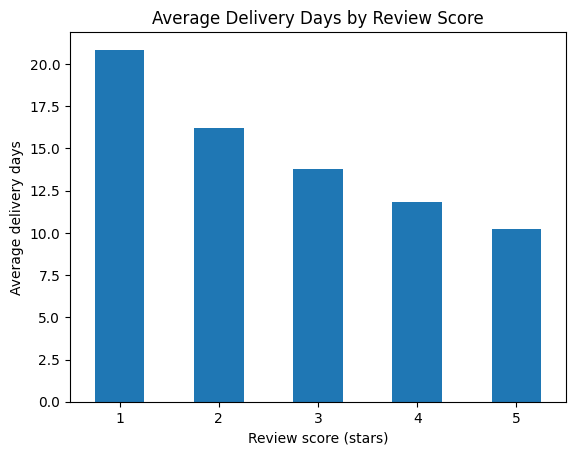

In [25]:
# Step 1: keep only delivered orders
delivered = orders[orders['order_delivered_customer_date'].notnull()].copy()

# Step 2: calculate delivery time in days
delivered['delivery_days'] = (delivered['order_delivered_customer_date'] -
                              delivered['order_purchase_timestamp']).dt.days

# Step 3: merge with reviews
delivery_reviews = delivered.merge(reviews, on='order_id')

# Step 4: correlation
correlation = delivery_reviews['delivery_days'].corr(delivery_reviews['review_score'])
print("Correlation between delivery days and review score:", round(correlation, 3))
print()

# Step 5: average delivery days per review score
avg_delivery = delivery_reviews.groupby('review_score')['delivery_days'].mean()
print(avg_delivery)

# Step 6: bar chart
avg_delivery.plot(kind='bar', title='Average Delivery Days by Review Score',
                  xlabel='Review score (stars)', ylabel='Average delivery days',
                  rot=0)
plt.show()


**Observations:**
- There is a clear negative relationship between delivery time and review score: the longer an order takes to arrive, the lower the review tends to be.
- Average delivery time rises steadily as scores fall, from about 10 days for 5-star reviews to about 21 days for 1-star reviews, roughly double.
- The correlation of -0.334 indicates a moderate relationship. Delivery speed matters, but other factors (product quality, order accuracy, customer service) also affect reviews.
- Correlation does not prove causation, but the pattern strongly suggests that faster delivery could improve customer satisfaction. This is an actionable finding for the business.



In [26]:
print(category_summary)
print()
print("Total revenue (all categories):", round(df['revenue'].sum(), 2))

                               total_revenue  avg_review  n_items
product_category_name_english                                    
health_beauty                     1434501.78    4.142768     9645
watches_gifts                     1297404.23    4.019160     5950
bed_bath_table                    1244950.00    3.895663    11137
sports_leisure                    1155295.28    4.107986     8640
computers_accessories             1062184.42    3.930819     7849
furniture_decor                    902472.18    3.903493     8331
housewares                         775827.36    4.055019     6943
cool_stuff                         712954.07    4.146341     3772
auto                               678859.45    4.065512     4213
garden_tools                       581483.25    4.042735     4329

Total revenue (all categories): 15772164.69


---

## Question 10: Final Report

Write a **2–3 paragraph executive summary** of your findings as a markdown cell below. A good report answers:

- **What is the overall health of the business?** (Use Q3, Q8 — order volumes and trends)
- **Which product categories should we double down on?** (Use Q6 — revenue + review scores together)
- **Where are our customers and how do we serve them?** (Use Q7, Q9 — geography and delivery speed)
- **What is one specific recommendation you would make to the leadership team?**

Write as if you're presenting to a non-technical executive. Use plain language. Reference specific numbers from your analysis.

*Skills: Sprint 4 Ch 06 (analytical reporting)*

## Executive Summary

### Business Health
Olist is a healthy, growing marketplace. Of the 99,441 orders in our data, 97% were successfully delivered, and cancellations and other problems make up only a small share. Order volume grew quickly through 2017, from about 800 orders in January to a peak of 7,544 in November (likely driven by Black Friday), and then held steady at roughly 6,100–7,300 orders per month through August 2018. The very low counts in late 2016 and in September–October 2018 reflect incomplete data at the edges of the dataset, not real changes in demand.

### Top Categories
Our top three revenue categories are health & beauty (R\$1.43M), watches & gifts (R\$1.30M) and bed, bath & table (R\$1.24M), which together bring in about R\$3.98M, roughly 25% of total revenue. Customer satisfaction is fairly consistent across our ten largest categories, with average review scores between 3.90 and 4.15 out of 5, so we can grow our biggest categories without major quality concerns. Health & beauty stands out as the best category to double down on: it leads in revenue and has one of the highest review scores (4.14). Bed, bath & table sells more items than any other category (11,137) but has the lowest average review score in the top ten (3.90), so improving the customer experience there could have a large impact.

### Customer Geography & Delivery
Our customers are heavily concentrated in southeastern Brazil. São Paulo alone accounts for 41,746 orders, more than the next three states combined. Delivery speed has a clear effect on how customers rate us: orders that received 5-star reviews arrived in about 10 days on average, while 1-star orders took about 21 days, twice as long.

### Recommendation
We recommend investing in faster delivery, starting in São Paulo and the surrounding southeastern states, for example through regional warehouses or partnerships with local carriers. Because so many customers are concentrated in this region, faster delivery there would improve the experience for the largest share of our customers and is likely to raise review scores across the platform.
